In [1]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "matplotlib", "seaborn"
])

0

In [2]:
pip install scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [4]:

# ============================================================
# URBANKART CUSTOMER INTELLIGENCE HUB
# Regression Model Training, Evaluation and Model Saving
# ============================================================

import os
import joblib
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# STEP 1: LOAD DATASET
# ------------------------------------------------------------

file_path = r"C:\Users\Tejas\OneDrive\Desktop\KPMG new\UrbanKart_Customer_Analytics_Master.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# ------------------------------------------------------------
# STEP 2: DEFINE TARGET AND FEATURES
# ------------------------------------------------------------

target = "Annual_Revenue"

# Check that target exists
if target not in df.columns:
    raise ValueError(
        f"Target column '{target}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Exclude target, identifiers and potentially leaky columns
drop_columns = [
    "Index",
    "Customer_ID",
    "Customer_Name",
    "Annual_Revenue",
    "Customer_Lifetime_Value",
    "Customer_Value_Segment"
]

X = df.drop(columns=drop_columns, errors="ignore")
y = df[target]

# Remove rows with missing target values
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Remove infinite target values, if any
finite_rows = y.map(lambda value: abs(value) != float("inf"))
X = X.loc[finite_rows].copy()
y = y.loc[finite_rows].copy()

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

# ------------------------------------------------------------
# STEP 3: ENCODE CATEGORICAL FEATURES
# ------------------------------------------------------------

# Convert categorical columns into numeric dummy columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Replace infinite feature values with missing values
X = X.replace([float("inf"), -float("inf")], float("nan"))

# Ensure all features are numeric
X = X.astype(float)

print("\nEncoded features shape:", X.shape)

# Save feature names for future predictions
feature_columns = X.columns.tolist()

# ------------------------------------------------------------
# STEP 4: SPLIT DATA INTO TRAINING AND TESTING SETS
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

# ------------------------------------------------------------
# STEP 5: DEFINE REGRESSION MODELS
# ------------------------------------------------------------

models = {

    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=1.0))
    ]),

    "Lasso Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Lasso(alpha=0.1, max_iter=10000))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", DecisionTreeRegressor(
            random_state=42,
            max_depth=15
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            random_state=42
        ))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", ExtraTreesRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Hist Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", HistGradientBoostingRegressor(
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        ))
    ])
}

# ------------------------------------------------------------
# STEP 6: TRAIN AND EVALUATE MODELS
# ------------------------------------------------------------

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train model
    model.fit(X_train, y_train)

    # Predict on unseen test data
    predictions = model.predict(X_test)

    # Evaluate performance
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = mean_squared_error(y_test, predictions) ** 0.5

    results.append({
        "Model": name,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    })

    trained_models[name] = model

    print(f"R2 Score: {r2:.4f}")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")

# ------------------------------------------------------------
# STEP 7: COMPARE ALL MODELS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("\n======================================")
print("REGRESSION MODEL COMPARISON")
print("======================================")

print(results_df.to_string(index=False))

# ------------------------------------------------------------
# STEP 8: SELECT BEST MODEL
# ------------------------------------------------------------

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

best_r2 = results_df.loc[0, "R2 Score"]
best_mae = results_df.loc[0, "MAE"]
best_rmse = results_df.loc[0, "RMSE"]

print("\n======================================")
print("BEST MODEL")
print("======================================")

print("Model:", best_model_name)
print(f"R2 Score: {best_r2:.4f}")
print(f"MAE: {best_mae:.2f}")
print(f"RMSE: {best_rmse:.2f}")

# ------------------------------------------------------------
# STEP 9: SAVE BEST MODEL AND FEATURE COLUMNS
# ------------------------------------------------------------

save_folder = "saved_models"
os.makedirs(save_folder, exist_ok=True)

model_path = os.path.join(
    save_folder,
    "best_revenue_model.pkl"
)

features_path = os.path.join(
    save_folder,
    "revenue_features.pkl"
)

# Save the trained pipeline and feature names
joblib.dump(best_model, model_path)
joblib.dump(feature_columns, features_path)

print("\nModel saved successfully!")
print("Model path:", os.path.abspath(model_path))
print("Feature path:", os.path.abspath(features_path))

# ------------------------------------------------------------
# STEP 10: TEST SAVED MODEL
# ------------------------------------------------------------

loaded_model = joblib.load(model_path)

sample_customer = X_test.iloc[[0]]
actual_revenue = y_test.iloc[0]

predicted_revenue = loaded_model.predict(sample_customer)[0]

print("\n======================================")
print("SAMPLE CUSTOMER PREDICTION")
print("======================================")

print(f"Actual Revenue:    {actual_revenue:.2f}")
print(f"Predicted Revenue: {predicted_revenue:.2f}")
print(f"Absolute Error:    {abs(actual_revenue - predicted_revenue):.2f}")

print("\nAll steps completed successfully!")


Dataset loaded successfully!
Dataset shape: (20000, 28)
  Customer_ID     Customer_Name  Age  Gender City_Tier     Income  \
0  CUST000001     Aryan Maharaj   23  Female    Tier 3   471173.0   
1  CUST000002       Udant Dewan   37  Female    Tier 2   150000.0   
2  CUST000003        Gagan Sami   36  Female    Tier 2  1089061.0   
3  CUST000004  Ayushman Chander   40    Male    Tier 1   661655.0   
4  CUST000005      Viraj Tiwari   58    Male    Tier 1   220959.0   

   Customer_Tenure_Months Acquisition_Channel  Website_Visits_Monthly  \
0                      54       Offline Store                     8.0   
1                      28      Organic Search                    20.0   
2                      18           Affiliate                     9.0   
3                      11        Social Media                     9.0   
4                      10        Social Media                    11.0   

   App_Sessions_Monthly  ...  Payment_Delay_Count  Loyalty_Points  \
0                  12

In [5]:

# ============================================================
# URBANKART CUSTOMER INTELLIGENCE HUB
# Regression Model Training, Evaluation and Model Saving
# ============================================================

import os
import joblib
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ------------------------------------------------------------
# STEP 1: LOAD DATASET
# ------------------------------------------------------------

file_path = r"C:\Users\Tejas\OneDrive\Desktop\KPMG new\UrbanKart_Customer_Analytics_Master.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# ------------------------------------------------------------
# STEP 2: DEFINE TARGET AND FEATURES
# ------------------------------------------------------------

target = "Annual_Revenue"

# Check that target exists
if target not in df.columns:
    raise ValueError(
        f"Target column '{target}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Exclude target, identifiers and potentially leaky columns
drop_columns = [
    "Index",
    "Customer_ID",
    "Customer_Name",
    "Annual_Revenue",
    "Customer_Lifetime_Value",
    "Customer_Value_Segment"
]

X = df.drop(columns=drop_columns, errors="ignore")
y = df[target]

# Remove rows with missing target values
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Remove infinite target values, if any
finite_rows = y.map(lambda value: abs(value) != float("inf"))
X = X.loc[finite_rows].copy()
y = y.loc[finite_rows].copy()

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

# ------------------------------------------------------------
# STEP 3: ENCODE CATEGORICAL FEATURES
# ------------------------------------------------------------

# Convert categorical columns into numeric dummy columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Replace infinite feature values with missing values
X = X.replace([float("inf"), -float("inf")], float("nan"))

# Ensure all features are numeric
X = X.astype(float)

print("\nEncoded features shape:", X.shape)

# Save feature names for future predictions
feature_columns = X.columns.tolist()

# ------------------------------------------------------------
# STEP 4: SPLIT DATA INTO TRAINING AND TESTING SETS
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

# ------------------------------------------------------------
# STEP 5: DEFINE REGRESSION MODELS
# ------------------------------------------------------------

models = {

    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=1.0))
    ]),

    "Lasso Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Lasso(alpha=0.1, max_iter=10000))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", DecisionTreeRegressor(
            random_state=42,
            max_depth=15
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            random_state=42
        ))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", ExtraTreesRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Hist Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", HistGradientBoostingRegressor(
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        ))
    ])
}

# ------------------------------------------------------------
# STEP 6: TRAIN AND EVALUATE MODELS
# ------------------------------------------------------------

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train model
    model.fit(X_train, y_train)

    # Predict on unseen test data
    predictions = model.predict(X_test)

    # Evaluate performance
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = mean_squared_error(y_test, predictions) ** 0.5

    results.append({
        "Model": name,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    })

    trained_models[name] = model

    print(f"R2 Score: {r2:.4f}")
    print(f"MAE: {mae:.2f}")
    print(f"RMSE: {rmse:.2f}")

# ------------------------------------------------------------
# STEP 7: COMPARE ALL MODELS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("\n======================================")
print("REGRESSION MODEL COMPARISON")
print("======================================")

print(results_df.to_string(index=False))

# ------------------------------------------------------------
# STEP 8: SELECT BEST MODEL
# ------------------------------------------------------------

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

best_r2 = results_df.loc[0, "R2 Score"]
best_mae = results_df.loc[0, "MAE"]
best_rmse = results_df.loc[0, "RMSE"]

print("\n======================================")
print("BEST MODEL")
print("======================================")

print("Model:", best_model_name)
print(f"R2 Score: {best_r2:.4f}")
print(f"MAE: {best_mae:.2f}")
print(f"RMSE: {best_rmse:.2f}")

# ------------------------------------------------------------
# STEP 9: SAVE BEST MODEL AND FEATURE COLUMNS
# ------------------------------------------------------------

save_folder = "saved_models"
os.makedirs(save_folder, exist_ok=True)

model_path = os.path.join(
    save_folder,
    "best_revenue_model.pkl"
)

features_path = os.path.join(
    save_folder,
    "revenue_features.pkl"
)

# Save the trained pipeline and feature names
joblib.dump(best_model, model_path)
joblib.dump(feature_columns, features_path)

print("\nModel saved successfully!")
print("Model path:", os.path.abspath(model_path))
print("Feature path:", os.path.abspath(features_path))

# ------------------------------------------------------------
# STEP 10: TEST SAVED MODEL
# ------------------------------------------------------------

loaded_model = joblib.load(model_path)

sample_customer = X_test.iloc[[0]]
actual_revenue = y_test.iloc[0]

predicted_revenue = loaded_model.predict(sample_customer)[0]

print("\n======================================")
print("SAMPLE CUSTOMER PREDICTION")
print("======================================")

print(f"Actual Revenue:    {actual_revenue:.2f}")
print(f"Predicted Revenue: {predicted_revenue:.2f}")
print(f"Absolute Error:    {abs(actual_revenue - predicted_revenue):.2f}")

print("\nAll steps completed successfully!")


Dataset loaded successfully!
Dataset shape: (20000, 28)
  Customer_ID     Customer_Name  Age  Gender City_Tier     Income  \
0  CUST000001     Aryan Maharaj   23  Female    Tier 3   471173.0   
1  CUST000002       Udant Dewan   37  Female    Tier 2   150000.0   
2  CUST000003        Gagan Sami   36  Female    Tier 2  1089061.0   
3  CUST000004  Ayushman Chander   40    Male    Tier 1   661655.0   
4  CUST000005      Viraj Tiwari   58    Male    Tier 1   220959.0   

   Customer_Tenure_Months Acquisition_Channel  Website_Visits_Monthly  \
0                      54       Offline Store                     8.0   
1                      28      Organic Search                    20.0   
2                      18           Affiliate                     9.0   
3                      11        Social Media                     9.0   
4                      10        Social Media                    11.0   

   App_Sessions_Monthly  ...  Payment_Delay_Count  Loyalty_Points  \
0                  12

,Model,R2 Score,MAE,RMSE
0,Hist Gradient Boosting,0.783,14843.904,21443.868
1,Gradient Boosting,0.782,14908.196,21518.188
2,Lasso Regression,0.777,15469.318,21755.091
3,Ridge Regression,0.777,15469.365,21755.092
4,Extra Trees,0.776,15363.880,21826.979
5,Random Forest,0.773,15427.082,21938.728
6,Linear Regression,0.739,16970.241,23526.619
7,Decision Tree,0.571,20246.696,30180.584


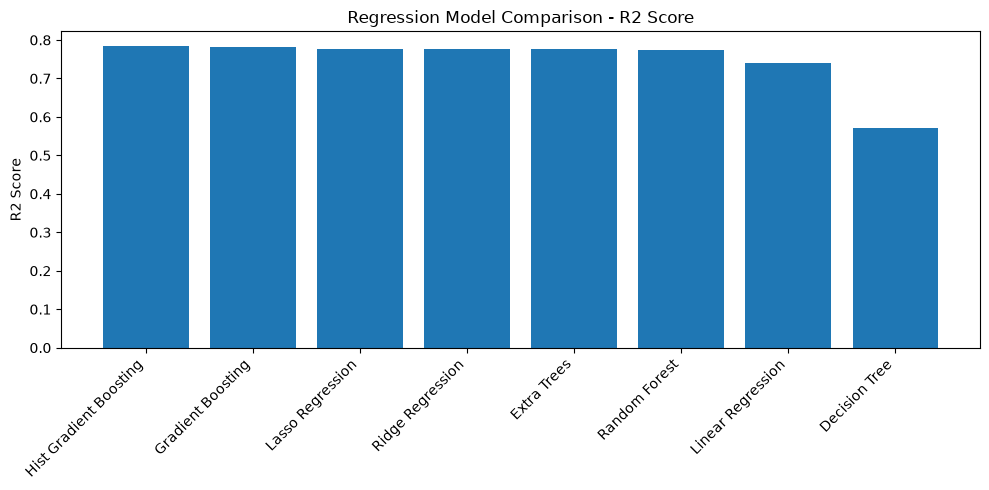

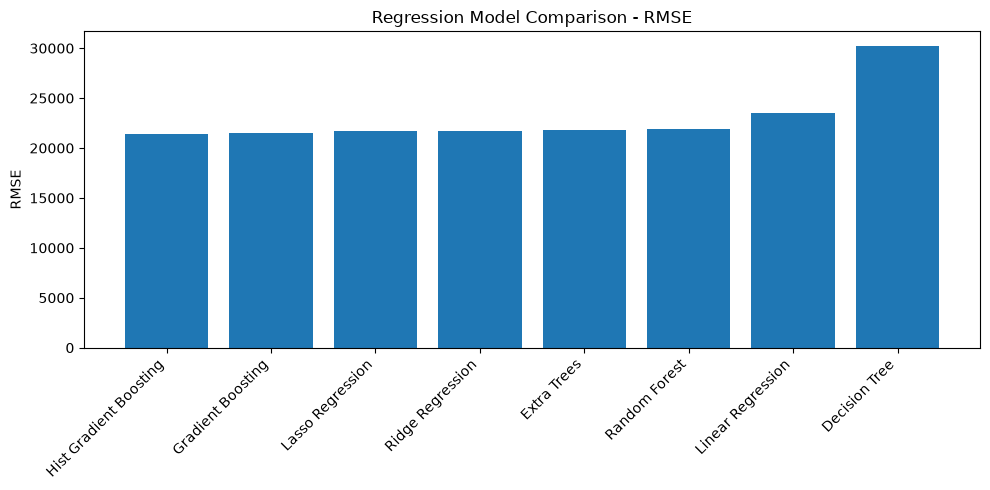

In [ ]:

import matplotlib.pyplot as plt

# Display the model comparison table
display(results_df.round(3))

# Compare R2 scores
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("R2 Score")
plt.title("Regression Model Comparison - R2 Score")
plt.tight_layout()
plt.show()

# Compare RMSE
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE")
plt.title("Regression Model Comparison - RMSE")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

print("Cross-validation scores:", cv_scores)
print("Mean CV R2:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))


Cross-validation scores: [0.79424882 0.76411639 0.80053257 0.79175386 0.79829075]
Mean CV R2: 0.7898
Standard deviation: 0.0132


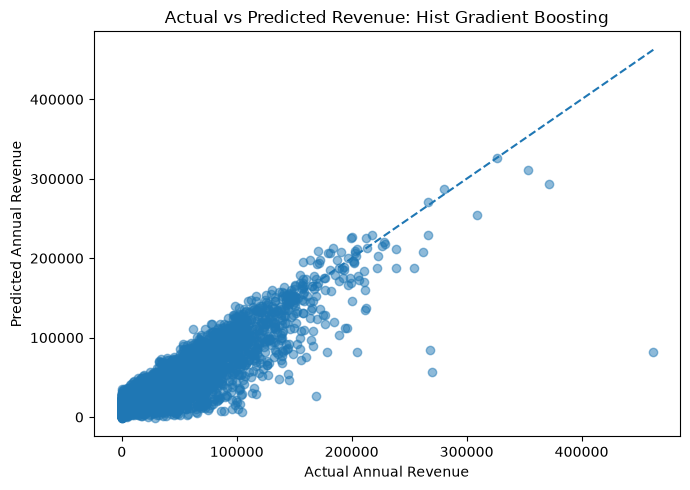

In [ ]:

predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.5)

# Reference line for perfect predictions
lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.xlabel("Actual Annual Revenue")
plt.ylabel("Predicted Annual Revenue")
plt.title(f"Actual vs Predicted Revenue: {best_model_name}")
plt.tight_layout()
plt.show()


In [ ]:

# Retrain the selected model using all available records
best_model.fit(X, y)

# Save the final model
joblib.dump(
    best_model,
    "saved_models/best_revenue_model.pkl"
)

joblib.dump(
    feature_columns,
    "saved_models/revenue_features.pkl"
)

print("Final model saved successfully!")


Final model saved successfully!


In [6]:

import os
import joblib

# Create folder to save the model
save_folder = r"C:\Users\Tejas\OneDrive\Desktop\KPMG new\saved_models"
os.makedirs(save_folder, exist_ok=True)

# Save the best trained model
model_path = os.path.join(
    save_folder,
    "best_revenue_model.pkl"
)

joblib.dump(best_model, model_path)

# Save feature columns
features_path = os.path.join(
    save_folder,
    "revenue_features.pkl"
)

joblib.dump(feature_columns, features_path)

print("Model saved successfully!")
print("Model location:", model_path)
print("Features location:", features_path)


Model saved successfully!
Model location: C:\Users\Tejas\OneDrive\Desktop\KPMG new\saved_models\best_revenue_model.pkl
Features location: C:\Users\Tejas\OneDrive\Desktop\KPMG new\saved_models\revenue_features.pkl


In [7]:

import joblib

loaded_model = joblib.load(
    r"C:\Users\Tejas\OneDrive\Desktop\KPMG new\saved_models\best_revenue_model.pkl"
)

print("Model loaded successfully!")
print("Selected model:", best_model_name)


Model loaded successfully!
Selected model: Hist Gradient Boosting
